In [3]:
"""多层感知机从0开始实现"""
import torch
from torch import nn
from d2l import torch as d2l


batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

In [4]:
# 两层MLP：784->256->10
num_inputs = 784    # 输入层的维度
num_hiddens = 256   # 隐藏层的神经元个数
num_outputs = 10     # 输出层的维度

# 第一层的参数:W1形状为784*256, b1形状为256
W1 = nn.Parameter(
    torch.randn(num_inputs, num_hiddens, requires_grad=True)
)
b1 = nn.Parameter(torch.zeros(num_hiddens, requires_grad=True))

# 第二层的参数:W2形状为256*10, b2形状为10
W2 = nn.Parameter(
    torch.randn(num_hiddens, num_outputs, requires_grad=True)
)
b2 = nn.Parameter(torch.zeros(num_outputs, requires_grad=True))

# 把所有可学习参数放进一个列表，方便之后一次性传给优化器
params = [W1, b1, W2, b2]

In [5]:
def relu(X):
    """ReLU激活函数"""
    a = torch.zeros_like(X)
    return torch.max(X, a)

In [6]:
# 实现MLP模型
def net(X):
    """多层感知机模型"""
    X = X.reshape((-1, num_inputs)) # 将输入X展平为二维张量
    H = relu(X @ W1 + b1)
    return (H @ W2 + b2)

loss = nn.CrossEntropyLoss() # 交叉熵损失函数

In [7]:
# ---------- 精度计算 ----------
def accuracy(y_hat, y):
    # y_hat是二维的且类别数大于1时，取每一行最大值的列索引作为预测类别
    if len(y_hat.shape) > 1 and y_hat.shape[1] > 1:
        y_hat = y_hat.argmax(axis=1)
    # 将y_hat的数据类型转换成y的，并进行比较
    cmp = (y_hat.type(y.dtype) == y)
    return float(cmp.type(y.dtype).sum())


# ---------- 测试集精度评估 ----------
def evaluate_accuracy(net, data_iter):
    """计算在指定数据集上模型的精度"""
    if isinstance(net, torch.nn.Module):
        net.eval()  # 将模型设置为评估模式
    metric = d2l.Accumulator(2)  # 累加器，存储：[正确预测数，预测总数]
    for X, y in data_iter:
        metric.add(accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]


# ---------- 一个epoch的训练 ----------
def train_epoch_ch3(net, train_iter, loss, updater):
    if isinstance(net, torch.nn.Module):
        net.train()  # 如果是标准的Pytorch模型，则将模型设置为训练模式
    metric = d2l.Accumulator(3)  # 训练损失总和，正确预测数，样本数
    for X, y in train_iter:
        y_hat = net(X)  # 1、前向传播，得到预测概率
        l = loss(y_hat, y)  # 2、计算当前batch的损失
        if isinstance(updater, torch.optim.Optimizer):
            """分支A:标准PyTorch优化器"""
            updater.zero_grad() # 3、梯度清零
            l.backward()    # 4、反向传播，计算梯度
            updater.step()  # 5、更新参数(W, b)
            metric.add(
                float(l) * len(y),  # 累加训练损失
                accuracy(y_hat, y),  # 累加正确预测数
                y.size().numel()  # 累加样本数,直接.numel()则会返回张量中元素的总数
            )
        else:
            """分支B:自定义优化器"""
            l.sum().backward()  # 3、反向传播
            updater(X.shape[0])  # 4、更新参数(W, b)，传入batch_size
            metric.add(
                float(l.sum()),  # 累加训练损失
                accuracy(y_hat, y),  # 累加正确预测数
                y.size().numel()  # 累加样本数
            )
    # 返回平均损失和准确率
    return metric[0] / metric[2], metric[1] / metric[2]  


# ---------- 完整训练函数 train_ch3 ----------
# 训练模型
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):
    # 初始化动画绘制器
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        # 训练模型一个迭代周期
        train_metrics = train_epoch_ch3(net, train_iter, loss, updater)
        # 评估模型在测试集上的准确率
        test_acc = evaluate_accuracy(net, test_iter)
        # 更新动画绘制器
        animator.add(epoch + 1, train_metrics + (test_acc,))
    # 解包训练损失和准确率
    train_loss, train_acc = train_metrics
    

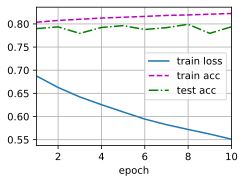

In [10]:
num_epochs, lr = 10, 0.1
updater = torch.optim.SGD(params, lr=lr) # 优化器

train_ch3(net, train_iter, test_iter, loss, num_epochs, updater);